# Mental Health in the Tech Industry — Exploratory Data Analysis

This notebook explores five years (2014, 2016, 2017, 2018 and 2019) of the **Open Sourcing
Mental Illness (OSMI) Mental Health in Tech Survey**, a voluntary, self-reported survey of
professionals working in the technology sector. The raw dataset contains **236,898 individual
answers**, given by **4,218 respondents**, across **105 unique questions** (the Kaggle
documentation notes that some questions are effectively repeated year over year under different
question IDs).

Out of those 105 questions, this analysis focuses on a small subset that is directly relevant to
two research questions about mental illness in the tech workplace — see the
[Table of Contents](#toc) below. The remaining questions are outside the scope of this notebook
but remain available in the underlying dataset for further work.

<a id="toc"></a>
## Table of Contents

1. [Project Overview & Research Questions](#sec-1)
2. [Library Imports](#sec-2)
3. [Data Acquisition](#sec-3)
4. [Data Cleaning & Preparation](#sec-4)
    - 4.1 [Loading the Survey Responses](#sec-4-1)
    - 4.2 [Removing Duplicate Responses](#sec-4-2)
    - 4.3 [Reshaping the Data](#sec-4-3)
    - 4.4 [Assessing Missing Data](#sec-4-4)
    - 4.5 [Selecting the Questions Used in this Analysis](#sec-4-5)
    - 4.6 [Building the Analysis Dataset](#sec-4-6)
5. [Helper Functions for Visual Exploration](#sec-5)
6. [Research Question 1 — Prevalence of Mental Illness in Tech](#sec-6)
    - 6.1 [Overall Prevalence](#sec-6-1)
    - 6.2 [Does It Vary by Country?](#sec-6-2)
    - 6.3 [Does It Vary by Gender?](#sec-6-3)
    - 6.4 [Does It Vary by Employment Type?](#sec-6-4)
7. [Research Question 2 — Comfort Discussing Mental Health with Coworkers](#sec-7)
    - 7.1 [Overall Comfort Level](#sec-7-1)
    - 7.2 [Does It Vary by Gender?](#sec-7-2)
8. [Conclusions](#sec-8)
9. [References & Data Source](#sec-9)

<a id="sec-1"></a>
## 1. Project Overview & Research Questions

Mental health in the technology industry has become an increasingly visible topic, yet it is
still often under-discussed in the workplace. This notebook uses the OSMI survey data to
investigate two questions:

**Research Question 1 — Prevalence.** What is the probability that a person working in tech has
been diagnosed with a mental illness, and does that probability differ by:
  - a) country (United States vs. the rest of the world)?
  - b) gender?
  - c) employment type (self-employed vs. employee)?

**Research Question 2 — Openness.** What proportion of tech workers feel comfortable discussing a
mental health issue with their coworkers, and does that proportion differ by gender?

Each question is answered by estimating the sampling distribution of the mean of a binary
indicator (via repeated resampling), visualizing it with kernel density estimates (KDE), and
confirming the observed differences with independent two-sample t-tests at a 95% confidence
level.

<a id="sec-2"></a>
## 2. Library Imports

`pandas` handles tabular data, `kagglehub` downloads the dataset from Kaggle, `sqlite3`/`os`
read the underlying SQLite database, `matplotlib`/`seaborn` produce the visualizations, `numpy`
supports numerical operations, and `scipy.stats` provides the hypothesis tests used later in the
notebook.

In [1]:
import pandas as pd
import kagglehub
import sqlite3
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats

<a id="sec-3"></a>
## 3. Data Acquisition

The dataset is downloaded from Kaggle
([`anth7310/mental-health-in-the-tech-industry`](https://www.kaggle.com/datasets/anth7310/mental-health-in-the-tech-industry))
and opened as a SQLite database.

In [2]:
path = kagglehub.dataset_download("anth7310/mental-health-in-the-tech-industry")
file = "mental_health.sqlite"
conn = sqlite3.connect(os.path.join(path,file))

<a id="sec-4"></a>
## 4. Data Cleaning & Preparation

The raw data is stored in a long format — one row per (survey, user, question) — and needs to be
cleaned, reshaped, and filtered before it can be analyzed.

<a id="sec-4-1"></a>
### 4.1 Loading the Survey Responses

The `Answer` table is loaded in full, which gives a first sense of the scale of the dataset.

In [3]:
query = "SELECT * FROM Answer"
answers = pd.read_sql_query(query,conn)
answers.shape,answers.columns, answers.UserID.nunique(),answers.SurveyID.nunique(),answers.QuestionID.nunique()

((236898, 4),
 Index(['AnswerText', 'SurveyID', 'UserID', 'QuestionID'], dtype='object'),
 4218,
 5,
 105)

<a id="sec-4-2"></a>
### 4.2 Removing Duplicate Responses

According to the Kaggle documentation, a duplicate occurs when the same user answers the same
survey more than once within the same year. Since the dataset does not explicitly record
submission order, rows are assumed to be stored chronologically, and the **last** answer is kept
for each (survey, user, question) combination.

In [4]:
answers[['SurveyID',"UserID","QuestionID"]].duplicated().value_counts()

False    234640
True       2258
Name: count, dtype: int64

In [5]:
answers_no_duplicates = answers.drop_duplicates(subset=['SurveyID',"UserID","QuestionID"],keep='last').copy()
(len(answers)-len(answers_no_duplicates))/len(answers)*100

0.9531528337090225

Duplicates account for less than 1% of the data, so dropping them has a negligible impact on the
overall sample size.

<a id="sec-4-3"></a>
### 4.3 Reshaping the Data

To analyze respondents rather than individual answers, the long-format table is pivoted into a
wide format with one row per (survey, user) and one column per question.

In [6]:
answers_by_question = answers_no_duplicates.pivot_table(
    index=["SurveyID","UserID"],
    columns="QuestionID",
    values="AnswerText",
    aggfunc="first"
).reset_index()
answers_by_question.columns.name = None

<a id="sec-4-4"></a>
### 4.4 Assessing Missing Data

Not every respondent answered every question. The percentage of missing values is computed per
question and its distribution is visualized below; questions with more than 60% missing data are
dropped, since they do not carry enough information to support a reliable analysis.

In [7]:
percentage_nan = (answers_by_question.isna().sum()/len(answers_by_question)*100).reset_index().rename(columns={0:"percentage"})

<Axes: xlabel='percentage', ylabel='Count'>

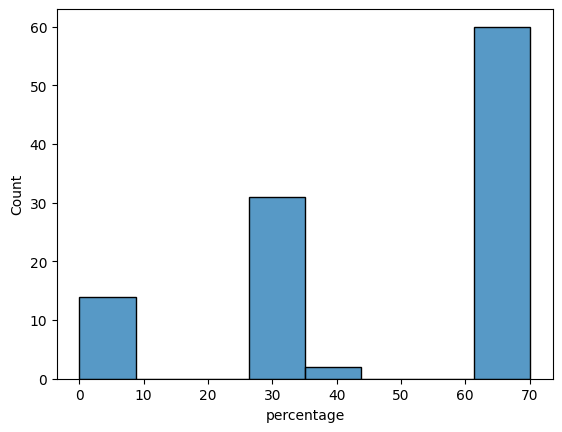

In [8]:
sns.histplot(data=percentage_nan,x="percentage")

In [9]:
relevant_cols = percentage_nan[percentage_nan.percentage < 60]["index"].to_list()

<a id="sec-4-5"></a>
### 4.5 Selecting the Questions Used in this Analysis

The question catalog is loaded to read the full wording of every retained question, which makes
it possible to manually choose the ones relevant to the two research questions above.

In [10]:
query = "SELECT * FROM Question"
questions = pd.read_sql_query(query,conn)

In [11]:
pd.set_option('display.max_colwidth', None)
questions[questions.questionid.isin(relevant_cols)]

,questiontext,questionid
0,What is your age?,1
1,What is your gender?,2
2,What country do you live in?,3
3,"If you live in the United States, which state or territory do you live in?",4
4,Are you self-employed?,5
5,Do you have a family history of mental illness?,6
6,Have you ever sought treatment for a mental health disorder from a mental health professional?,7
7,How many employees does your company or organization have?,8
8,Is your employer primarily a tech company/organization?,9
9,Does your employer provide mental health benefits as part of healthcare coverage?,10


Out of all the retained questions, the following seven were selected for this analysis:

| Question ID | Question text | Column name used below |
|---|---|---|
| 1  | What is your age? | `age` |
| 2  | What is your gender? | `gender` |
| 5  | Are you self-employed? | `self_employed` |
| 18 | Would you feel comfortable discussing a mental health issue with your coworkers? | `discussing_mental_illness` |
| 33 | Have you ever been diagnosed with a mental health disorder? | `mental_illness_diagnosed` |
| 50 | What country do you work in? | `country` |
| 56 | Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace? | `bad_handling` |

`age` and `bad_handling` are kept in the working dataset for completeness but are not analyzed
further in this notebook, since they fall outside the two research questions defined in
[Section 1](#sec-1).

In [12]:
questionid_used = ["SurveyID","UserID",1,2,5,18,33,50,56]

In [13]:
answer_for_analysis = answers_by_question[questionid_used].copy()

<a id="sec-4-6"></a>
### 4.6 Building the Analysis Dataset

Each selected question is inspected and cleaned individually: categorical answers are normalized
(lower-cased, rare categories grouped into `"other"`), and missing or sentinel values (`-1`,
`NaN`) are replaced with an explicit `"Unknown"` / `"No answer"` category rather than dropped, to
keep as many respondents as possible.

In [14]:
answer_for_analysis[2].value_counts().reset_index()

,2,count
0,Male,2830
1,Female,914
2,male,212
3,female,110
4,-1,24
...,...,...
96,43,1
97,masculino,1
98,I am a Wookie,1
99,Trans non-binary/genderfluid,1


In [15]:
answer_for_analysis[2] = answers_by_question[2].str.lower()
answer_for_analysis.loc[~answer_for_analysis[2].isin(["male","female","other"]),2] = "other"
answer_for_analysis[2].value_counts()

2
male      3043
female    1024
other      151
Name: count, dtype: int64

In [16]:
answer_for_analysis[5].value_counts()

5
0     3550
1      650
-1      18
Name: count, dtype: int64

In [17]:
answer_for_analysis[18] = answer_for_analysis[18].fillna("No answer").replace({"-1":"No answer"})
answer_for_analysis[18].value_counts(dropna=False)

18
No answer    1764
Maybe        1053
No            719
Yes           682
Name: count, dtype: int64

In [18]:
answer_for_analysis[33] = answer_for_analysis[33].replace({"Possibly":"Maybe"}).fillna("Don't Know")
answer_for_analysis[33].value_counts(dropna=False)

33
Don't Know    1384
Yes           1237
No             969
Maybe          628
Name: count, dtype: int64

In [19]:
answer_for_analysis[50] = answer_for_analysis[50].fillna("Unknown").replace({"-1":"Unknown"})
answer_for_analysis[50].value_counts()

50
United States of America    1872
Unknown                     1262
United Kingdom               300
Canada                       122
Germany                       90
                            ... 
Macedonia                      1
Georgia                        1
Ghana                          1
Botswana                       1
Algeria                        1
Name: count, Length: 77, dtype: int64

In [20]:
answer_for_analysis[56] = answer_for_analysis[56].fillna("Unknown").replace({"-1":"Unknown"})
answer_for_analysis[56].value_counts(dropna=False)

56
Unknown                           1351
No                                1207
Maybe/Not sure                     748
Yes, I observed                    541
Yes, I experienced                 356
I've always been self-employed      15
Name: count, dtype: int64

In [21]:
answer_for_analysis.columns = ["SurveyID","UserID","age","gender","self_employed","discussing_mental_illness","mental_illness_diagnosed","country","bad_handling"]

The cleaned dataset now has one row per respondent, with meaningful column names:

In [22]:
answer_for_analysis

,SurveyID,UserID,age,gender,self_employed,discussing_mental_illness,mental_illness_diagnosed,country,bad_handling
0,2014,1,37,female,-1,No answer,Don't Know,Unknown,Unknown
1,2014,2,44,male,-1,No answer,Don't Know,Unknown,Unknown
2,2014,3,32,male,-1,No answer,Don't Know,Unknown,Unknown
3,2014,4,31,male,-1,No answer,Don't Know,Unknown,Unknown
4,2014,5,31,male,-1,No answer,Don't Know,Unknown,Unknown
...,...,...,...,...,...,...,...,...,...
4213,2019,4214,27,male,0,No,Maybe,India,"Yes, I observed"
4214,2019,4215,48,male,1,No answer,No,United States of America,"Yes, I observed"
4215,2019,4216,50,male,1,No answer,No,India,I've always been self-employed
4216,2019,4217,30,female,0,Maybe,Maybe,India,Maybe/Not sure


<a id="sec-5"></a>
## 5. Helper Functions for Visual Exploration

Throughout this analysis, the same two visual elements are needed repeatedly for many subgroups:
(1) a kernel density estimate (KDE) of the sampling distribution of the mean, and (2) a summary
statistics table (`pandas.describe()`) placed next to it. Two small helper functions are defined
once and reused for every comparison below.

### `create_kde_plot`

Draws the KDE of the sample mean of a binary variable, estimated by repeatedly drawing samples of
size `n` and averaging them (a resampling-based approximation of the sampling distribution of the
mean). Optionally shades the two-tailed rejection region at a given significance level `alpha`.

In [23]:
def create_kde_plot(data,axs,label=None,samples=1000,n=100,show_tails=False,alpha=0.05):
    mean = []
    for i in range(samples):
        mean.append(data.sample(n).mean())
    mean = np.array(mean)
    kde = sns.kdeplot(mean,ax=axs,label=label)
    line = axs.lines[-1]
    color = line.get_color()
    mean_of_means = mean.mean()
    axs.axvline(
        mean_of_means,
        linestyle=":",
        color=color,
        label=f"{label} mean: {mean_of_means:.2f}"
    )

    if show_tails:
        se = mean.std(ddof=1)
        t_crit = stats.t.ppf(1 - alpha/2, df=n-1)
        lower, upper = mean_of_means - t_crit*se, mean_of_means + t_crit*se

        x, y = line.get_data()
        axs.fill_between(x, y, where=(x <= lower) | (x >= upper), color=color, alpha=0.3)
        axs.axvline(lower, linestyle="--", color="red", alpha=0.6, label=f"α={alpha}")
        axs.axvline(upper, linestyle="--", color="red", alpha=0.6)

### `create_describe_table`

A complementary function that renders `pandas.describe()` as a styled table directly inside a
matplotlib `Axes`, so it can be placed next to (or below) a `create_kde_plot` panel in the same
figure. It accepts either a single sample (with an optional `label`), or a `{label: sample}`
dictionary to compare several groups side by side in one table.

In [24]:
def create_describe_table(data, axs, label=None, precision=2):
    if isinstance(data, dict):
        summary = pd.DataFrame({name: series.describe() for name, series in data.items()})
    else:
        summary = data.describe().to_frame(name=label or data.name or "value")

    summary = summary.round(precision)

    axs.axis("off")
    table = axs.table(
        cellText=summary.values,
        rowLabels=summary.index,
        colLabels=summary.columns,
        cellLoc="center",
        rowLoc="center",
        loc="center",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(11)
    table.scale(1, 1.8)

    header_color = "#4C72B0"
    row_colors = ("#F2F2F2", "#FFFFFF")
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("#D9D9D9")
        if row == 0:
            cell.set_facecolor(header_color)
            cell.set_text_props(color="white", weight="bold")
        elif col == -1:
            cell.set_facecolor("#E8E8E8")
            cell.set_text_props(weight="bold")
        else:
            cell.set_facecolor(row_colors[row % 2])

    axs.set_title("Summary statistics (describe)", fontsize=12, weight="bold", pad=14)
    return table

<a id="sec-6"></a>
## 6. Research Question 1 — Prevalence of Mental Illness in Tech

<a id="sec-6-1"></a>
### 6.1 Overall Prevalence

In [25]:
answer_for_analysis["mental_illness_diagnosed_binary"] = answer_for_analysis.mental_illness_diagnosed.map({"Don't Know":-1,"Yes":1,"No":0,"Maybe":-1})

In [26]:
mental_illness = answer_for_analysis[answer_for_analysis.mental_illness_diagnosed_binary != -1]

Respondents who answered "Maybe" or "Don't Know" are excluded here, since the goal is to estimate
the probability among respondents with a definitive diagnosis status. The figure below shows the
estimated sampling distribution of the mean (i.e., of the diagnosis rate) together with its
summary statistics.

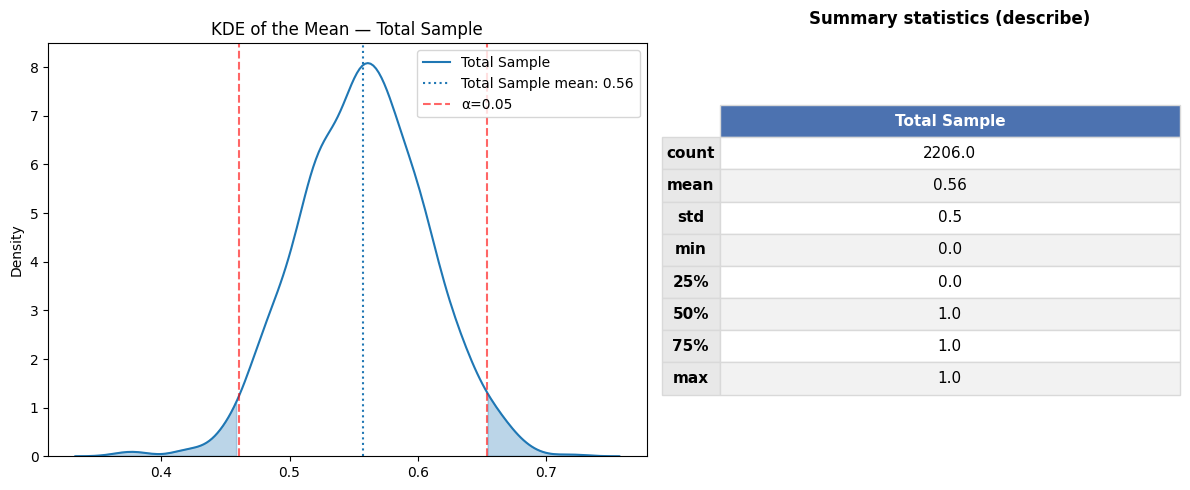

In [27]:
fig, axs = plt.subplot_mosaic([["kde", "table"]], figsize=(12, 5), width_ratios=[1.3, 1])

create_kde_plot(data=mental_illness.mental_illness_diagnosed_binary, axs=axs["kde"], show_tails=True, label="Total Sample")
axs["kde"].set_title("KDE of the Mean — Total Sample")
axs["kde"].legend()

create_describe_table(data=mental_illness.mental_illness_diagnosed_binary, axs=axs["table"], label="Total Sample")

plt.tight_layout()
plt.show()

Considering only respondents with a definitive answer, the mean diagnosis rate is approximately
**0.56** — that is, an estimated **56% probability** of having been diagnosed with a mental
illness while working in tech.

<a id="sec-6-2"></a>
### 6.2 Does It Vary by Country?

The sample is split between respondents working in the **United States** and everywhere else, to
see whether the diagnosis rate differs by location.

**Hypotheses** (for each comparison below — population vs. USA, and population vs. rest of world):
- H0: the subgroup mean is equal to the overall population mean.
- H1: the subgroup mean is different from the overall population mean.

Significance level: α = 0.05.

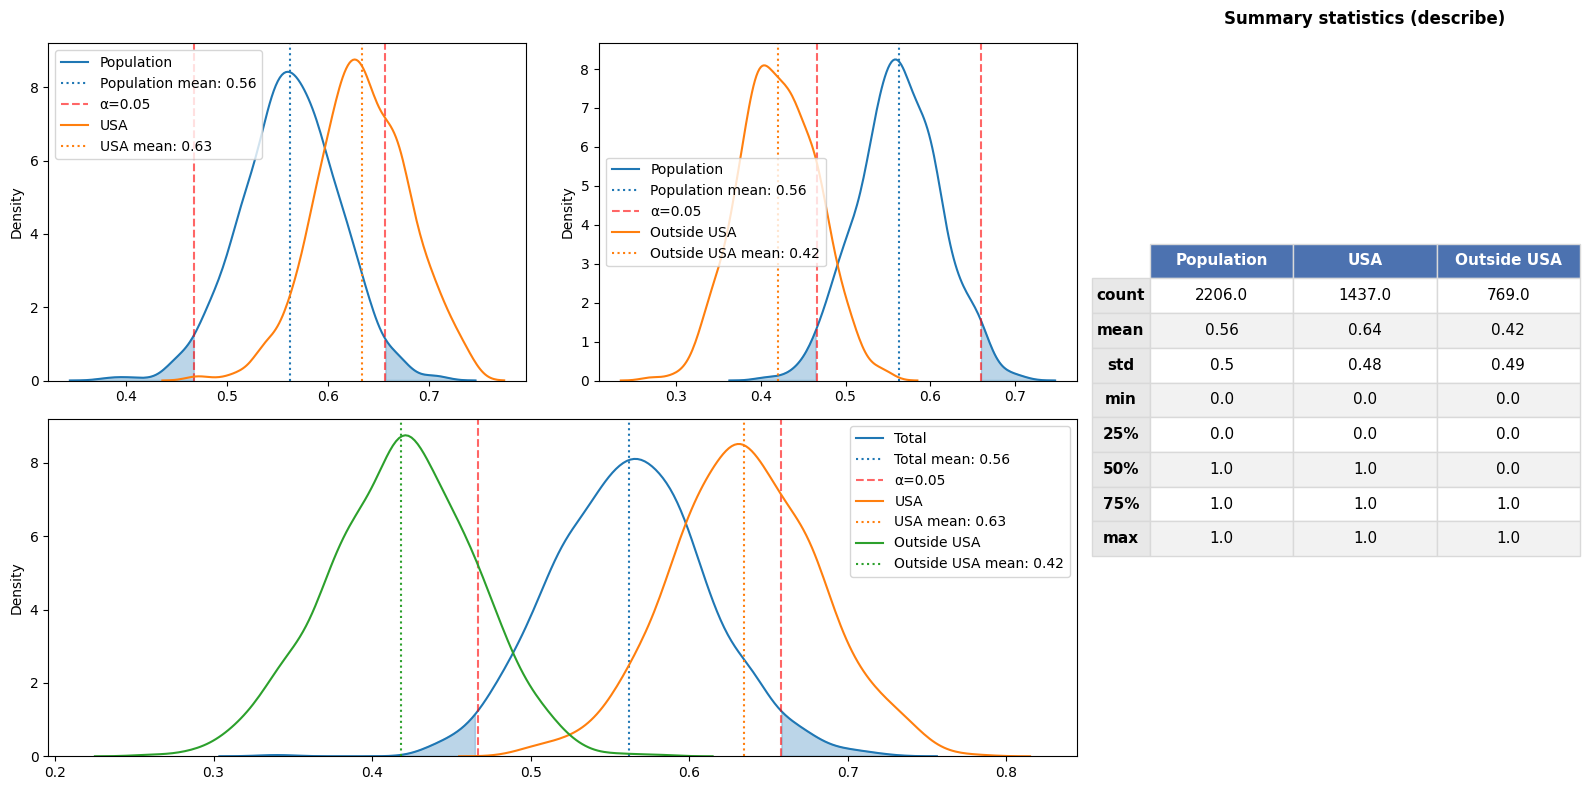

In [28]:
mental_illness_USA = mental_illness[mental_illness.country == "United States of America"]
mental_illness_no_USA = mental_illness[mental_illness.country != "United States of America"]

fig, axs = plt.subplot_mosaic(
    [
        ["top1", "top2", "table"],
        ["bottom", "bottom", "table"],
    ],
    figsize=(16, 8),
    width_ratios=[1, 1, 0.9],
)

create_kde_plot(data=mental_illness.mental_illness_diagnosed_binary, axs=axs["top1"], label="Population", show_tails=True)
create_kde_plot(data=mental_illness_USA.mental_illness_diagnosed_binary, axs=axs["top1"], label="USA")
create_kde_plot(data=mental_illness.mental_illness_diagnosed_binary, axs=axs["top2"], label="Population", show_tails=True)
create_kde_plot(data=mental_illness_no_USA.mental_illness_diagnosed_binary, axs=axs["top2"], label="Outside USA")
create_kde_plot(data=mental_illness.mental_illness_diagnosed_binary, axs=axs["bottom"], label="Total", show_tails=True)
create_kde_plot(data=mental_illness_USA.mental_illness_diagnosed_binary, axs=axs["bottom"], label="USA")
create_kde_plot(data=mental_illness_no_USA.mental_illness_diagnosed_binary, axs=axs["bottom"], label="Outside USA")

create_describe_table(
    data={
        "Population": mental_illness.mental_illness_diagnosed_binary,
        "USA": mental_illness_USA.mental_illness_diagnosed_binary,
        "Outside USA": mental_illness_no_USA.mental_illness_diagnosed_binary,
    },
    axs=axs["table"],
)

axs["top1"].legend()
axs["top2"].legend()
axs["bottom"].legend()
plt.tight_layout()
plt.show()

In [29]:
t, p = stats.ttest_ind(mental_illness.mental_illness_diagnosed_binary, mental_illness_USA.mental_illness_diagnosed_binary)
verdict = "rejected" if p < 0.05 else "not rejected"
comparison = "lower than" if p < 0.05 else "greater than or equal to"
print(f"H0 is {verdict}: the p-value ({p:.4g}) is {comparison} 0.05")

H0 is rejected: the p-value (6.125e-06) is lower than 0.05


In [30]:
t, p = stats.ttest_ind(mental_illness.mental_illness_diagnosed_binary, mental_illness_no_USA.mental_illness_diagnosed_binary, equal_var=True)
verdict = "rejected" if p < 0.05 else "not rejected"
comparison = "lower than" if p < 0.05 else "greater than or equal to"
print(f"H0 is {verdict}: the p-value ({p:.4g}) is {comparison} 0.05")

H0 is rejected: the p-value (1.464e-11) is lower than 0.05


Both comparisons reject H0 at the 95% confidence level: respondents working in the USA report a
diagnosis rate of approximately **63.6%**, compared to approximately **42.0%** for the rest of the
world — a statistically significant, and practically large, difference.

<a id="sec-6-3"></a>
### 6.3 Does It Vary by Gender?

**Hypotheses** (for each of the three gender subgroups vs. the overall population):
- H0: the subgroup mean is equal to the overall population mean.
- H1: the subgroup mean is different from the overall population mean.

Significance level: α = 0.05.

In [31]:
mental_illness_male = mental_illness[mental_illness.gender == "male"]

In [32]:
mental_illness_female = mental_illness[mental_illness.gender == "female"]

In [33]:
mental_illness_other = mental_illness[mental_illness.gender == "other"]

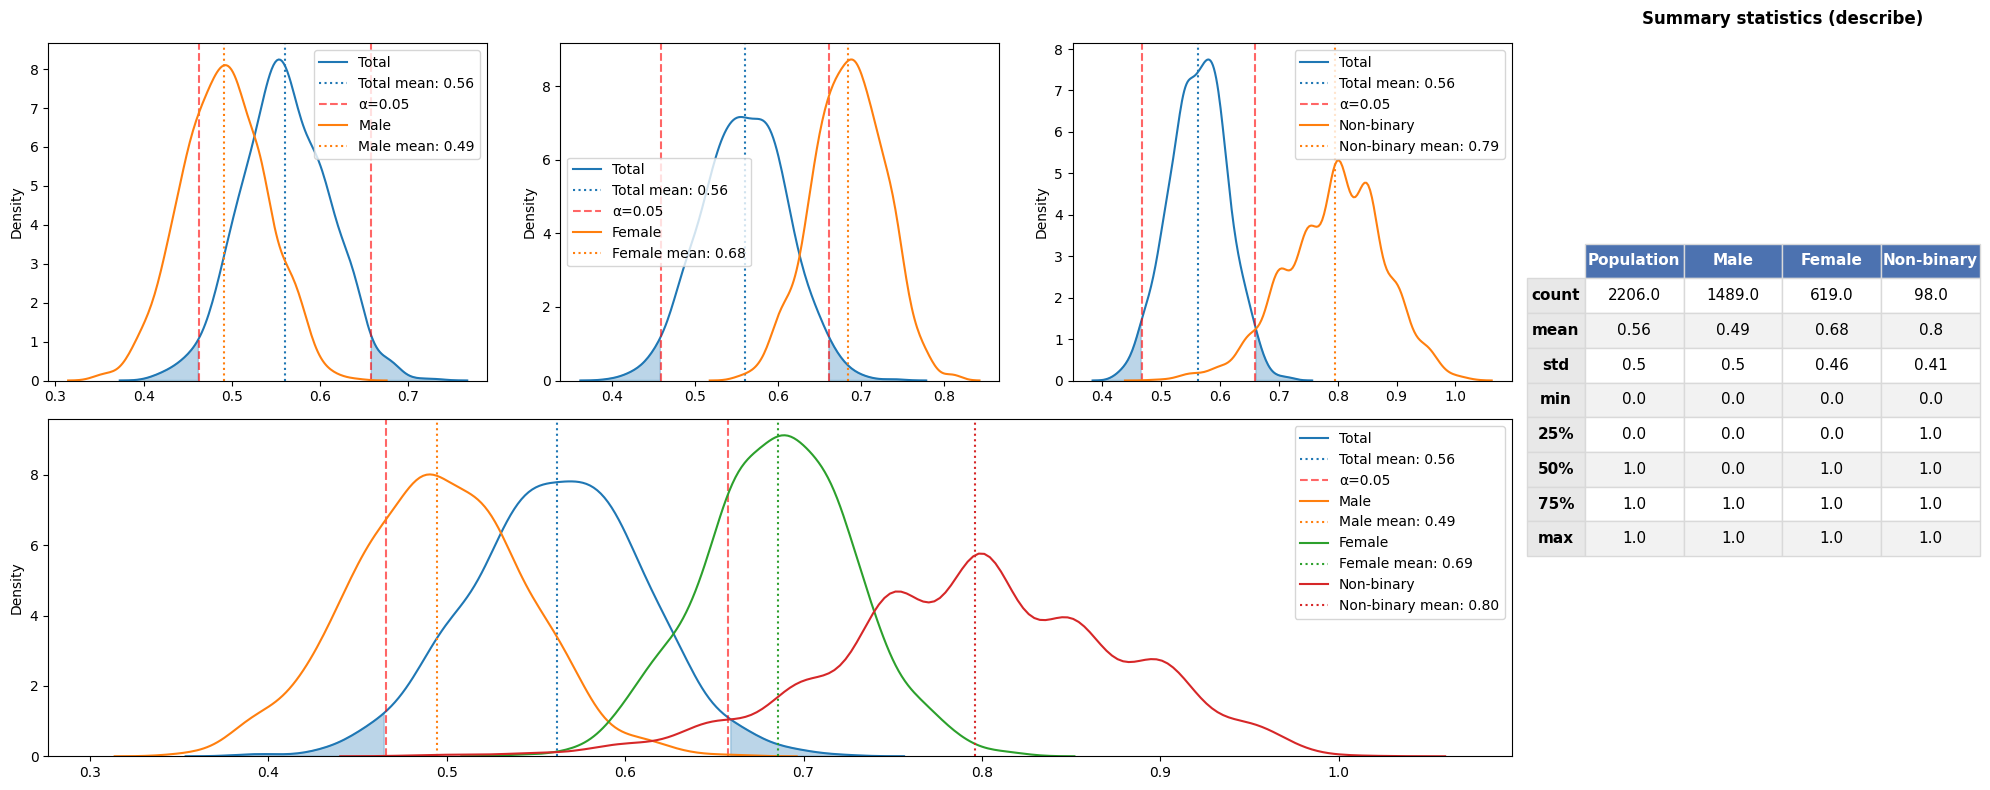

In [34]:
fig, axs = plt.subplot_mosaic(
    [
        ["top1", "top2", "top3", "table"],
        ["bottom", "bottom", "bottom", "table"],
    ],
    figsize=(20, 8),
    width_ratios=[1, 1, 1, 0.9],
)

create_kde_plot(data=mental_illness.mental_illness_diagnosed_binary,axs=axs["top1"],label="Total",show_tails=True)
create_kde_plot(data=mental_illness_male.mental_illness_diagnosed_binary, axs=axs["top1"], label="Male")
create_kde_plot(data=mental_illness.mental_illness_diagnosed_binary,axs=axs["top2"],label="Total",show_tails=True)
create_kde_plot(data=mental_illness_female.mental_illness_diagnosed_binary,axs=axs["top2"],label="Female")
create_kde_plot(data=mental_illness.mental_illness_diagnosed_binary,axs=axs["top3"],label="Total",show_tails=True)
create_kde_plot(data=mental_illness_other.mental_illness_diagnosed_binary,n=20,axs=axs["top3"],label="Non-binary")
create_kde_plot(data=mental_illness.mental_illness_diagnosed_binary,axs=axs["bottom"],label="Total",show_tails=True)
create_kde_plot(data=mental_illness_male.mental_illness_diagnosed_binary, axs=axs["bottom"], label="Male")
create_kde_plot(data=mental_illness_female.mental_illness_diagnosed_binary,axs=axs["bottom"],label="Female")
create_kde_plot(data=mental_illness_other.mental_illness_diagnosed_binary,n=20,axs=axs["bottom"],label="Non-binary")

create_describe_table(
    data={
        "Population": mental_illness.mental_illness_diagnosed_binary,
        "Male": mental_illness_male.mental_illness_diagnosed_binary,
        "Female": mental_illness_female.mental_illness_diagnosed_binary,
        "Non-binary": mental_illness_other.mental_illness_diagnosed_binary,
    },
    axs=axs["table"],
)

axs["top1"].legend()
axs["top2"].legend()
axs["top3"].legend()
axs["bottom"].legend()
plt.tight_layout()
plt.show()

In [35]:
t, p = stats.ttest_ind(mental_illness.mental_illness_diagnosed_binary,mental_illness_male.mental_illness_diagnosed_binary)
verdict = "rejected" if p < 0.05 else "not rejected"
comparison = "lower than" if p < 0.05 else "greater than or equal to"
print(f"H0 is {verdict}: the p-value ({p:.4g}) is {comparison} 0.05")

H0 is rejected: the p-value (5.95e-05) is lower than 0.05


In [36]:
t, p = stats.ttest_ind(mental_illness.mental_illness_diagnosed_binary,mental_illness_female.mental_illness_diagnosed_binary)
verdict = "rejected" if p < 0.05 else "not rejected"
comparison = "lower than" if p < 0.05 else "greater than or equal to"
print(f"H0 is {verdict}: the p-value ({p:.4g}) is {comparison} 0.05")

H0 is rejected: the p-value (2.668e-08) is lower than 0.05


In [37]:
t, p = stats.ttest_ind(mental_illness.mental_illness_diagnosed_binary,mental_illness_other.mental_illness_diagnosed_binary)
verdict = "rejected" if p < 0.05 else "not rejected"
comparison = "lower than" if p < 0.05 else "greater than or equal to"
print(f"H0 is {verdict}: the p-value ({p:.4g}) is {comparison} 0.05")

H0 is rejected: the p-value (4.016e-06) is lower than 0.05


All three subgroups differ significantly from the overall population mean: women
(approximately **68.5%**) and non-binary respondents (approximately **79.6%**, though based on a
much smaller sample of 98 respondents) report notably higher diagnosis rates than men
(approximately **49.4%**).

<a id="sec-6-4"></a>
### 6.4 Does It Vary by Employment Type?

**Hypotheses** (for each of the two subgroups vs. the overall population):
- H0: the subgroup mean is equal to the overall population mean.
- H1: the subgroup mean is different from the overall population mean.

Significance level: α = 0.05.

In [38]:
mental_illness_self_employee = mental_illness[mental_illness.self_employed == "1"]

In [39]:
mental_illness_employee = mental_illness[mental_illness.self_employed == "0"]

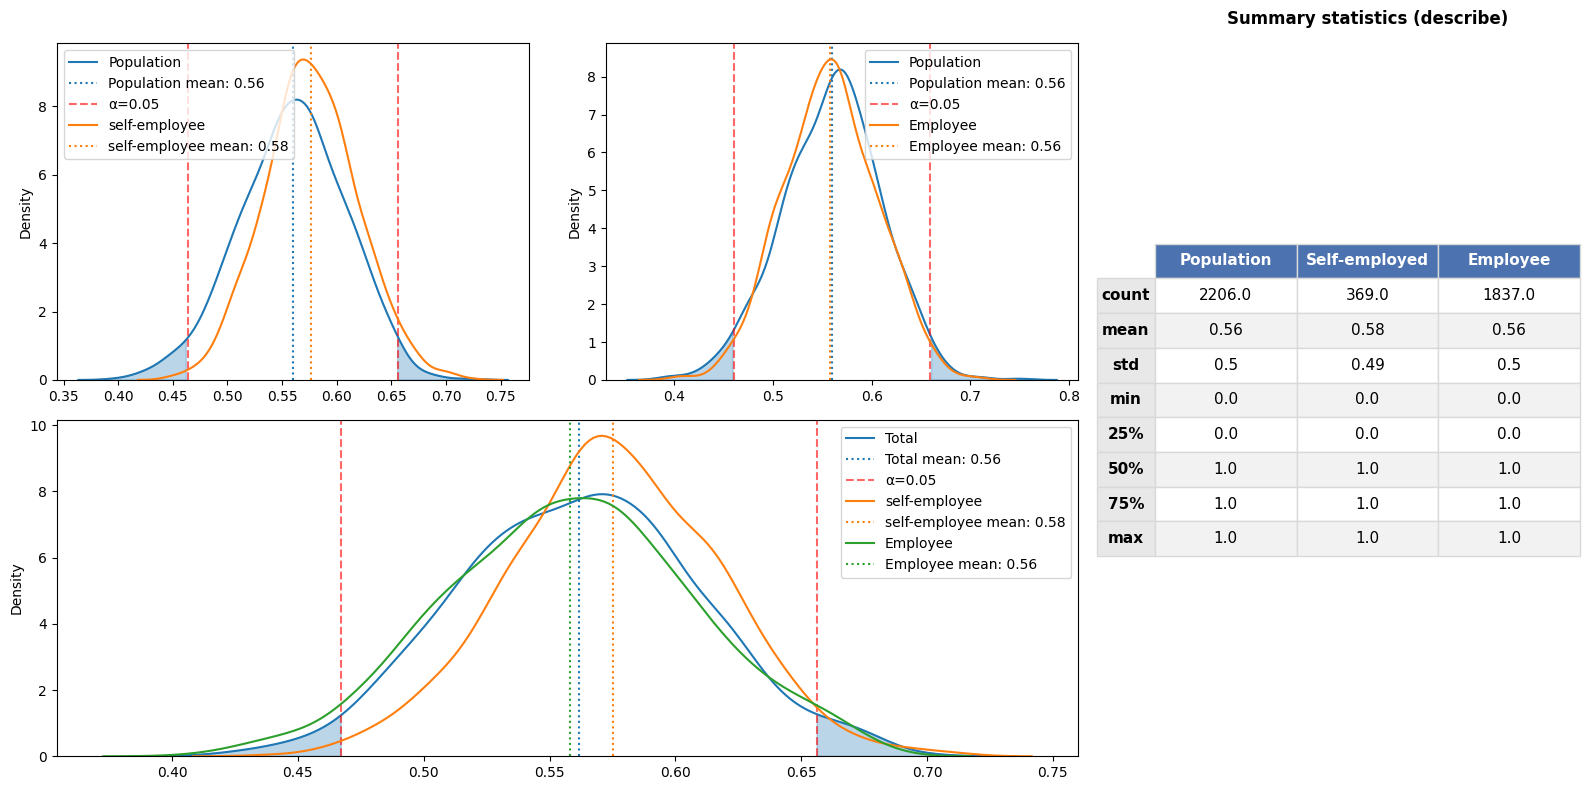

In [40]:
fig, axs = plt.subplot_mosaic(
    [
        ["top1", "top2", "table"],
        ["bottom", "bottom", "table"],
    ],
    figsize=(16, 8),
    width_ratios=[1, 1, 0.9],
)

create_kde_plot(data=mental_illness.mental_illness_diagnosed_binary, axs=axs["top1"], label="Population",show_tails=True)
create_kde_plot(data=mental_illness_self_employee.mental_illness_diagnosed_binary,axs=axs["top1"],label="self-employee")
create_kde_plot(data=mental_illness.mental_illness_diagnosed_binary, axs=axs["top2"], label="Population",show_tails=True)
create_kde_plot(data=mental_illness_employee.mental_illness_diagnosed_binary,axs=axs["top2"],label="Employee")
create_kde_plot(data=mental_illness.mental_illness_diagnosed_binary,axs=axs["bottom"],label="Total",show_tails=True)
create_kde_plot(data=mental_illness_self_employee.mental_illness_diagnosed_binary,axs=axs["bottom"],label="self-employee")
create_kde_plot(data=mental_illness_employee.mental_illness_diagnosed_binary,axs=axs["bottom"],label="Employee")

create_describe_table(
    data={
        "Population": mental_illness.mental_illness_diagnosed_binary,
        "Self-employed": mental_illness_self_employee.mental_illness_diagnosed_binary,
        "Employee": mental_illness_employee.mental_illness_diagnosed_binary,
    },
    axs=axs["table"],
)

axs["top1"].legend()
axs["top2"].legend()
axs["bottom"].legend()
plt.tight_layout()
plt.show()

In [41]:
t, p = stats.ttest_ind(mental_illness.mental_illness_diagnosed_binary,mental_illness_employee.mental_illness_diagnosed_binary)
verdict = "rejected" if p < 0.05 else "not rejected"
comparison = "lower than" if p < 0.05 else "greater than or equal to"
print(f"H0 is {verdict}: the p-value ({p:.4g}) is {comparison} 0.05")

H0 is not rejected: the p-value (0.8327) is greater than or equal to 0.05


In [42]:
t, p = stats.ttest_ind(mental_illness.mental_illness_diagnosed_binary,mental_illness_self_employee.mental_illness_diagnosed_binary)
verdict = "rejected" if p < 0.05 else "not rejected"
comparison = "lower than" if p < 0.05 else "greater than or equal to"
print(f"H0 is {verdict}: the p-value ({p:.4g}) is {comparison} 0.05")

H0 is not rejected: the p-value (0.5546) is greater than or equal to 0.05


Neither comparison reaches statistical significance: the data does not support a difference in
diagnosis rates between self-employed professionals (approximately **57.7%**) and salaried
employees (approximately **55.7%**).

<a id="sec-7"></a>
## 7. Research Question 2 — Comfort Discussing Mental Health with Coworkers

<a id="sec-7-1"></a>
### 7.1 Overall Comfort Level

In [43]:
answer_for_analysis.discussing_mental_illness.value_counts()
answer_for_analysis["discussing_mental_illness_binary"] = answer_for_analysis.discussing_mental_illness.map({"No answer":-1,"Maybe":-1,"No":0,"Yes":1})

In [44]:
discussing = answer_for_analysis[answer_for_analysis.discussing_mental_illness_binary != -1]

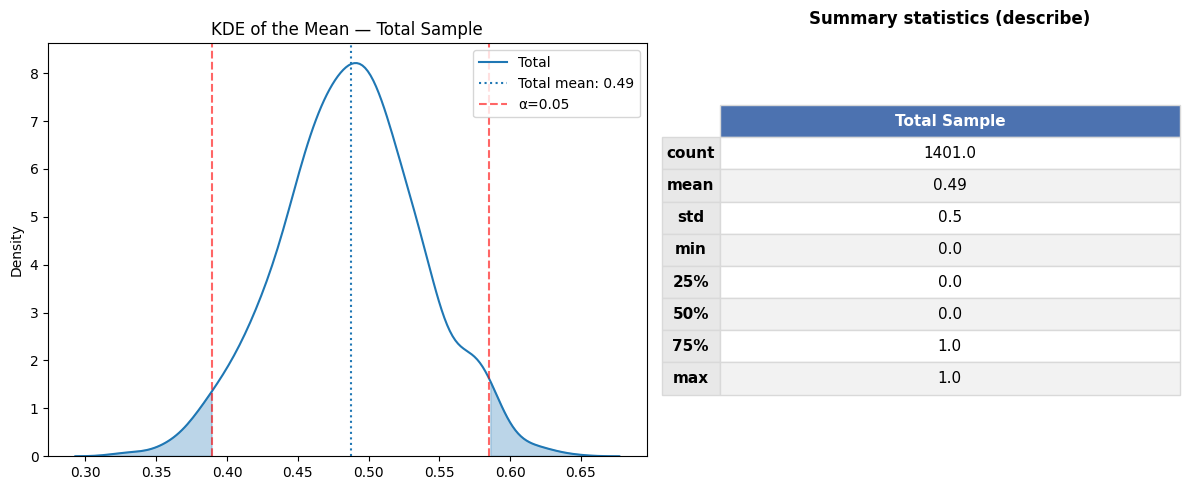

In [45]:
fig, axs = plt.subplot_mosaic([["kde", "table"]], figsize=(12, 5), width_ratios=[1.3, 1])

create_kde_plot(data=discussing.discussing_mental_illness_binary, axs=axs["kde"], label="Total", show_tails=True)
axs["kde"].set_title("KDE of the Mean — Total Sample")
axs["kde"].legend()

create_describe_table(data=discussing.discussing_mental_illness_binary, axs=axs["table"], label="Total Sample")

plt.tight_layout()
plt.show()

The estimated sampling distribution places the true proportion of tech workers comfortable
discussing a mental health issue with coworkers mostly between 40% and 55%, centered around
**48.7%** — meaning that, at best, roughly half of tech workers feel safe doing so.

<a id="sec-7-2"></a>
### 7.2 Does It Vary by Gender?

**Hypotheses** (for each of the three gender subgroups vs. the overall population):
- H0: the subgroup mean is equal to the overall population mean.
- H1: the subgroup mean is different from the overall population mean.

Significance level: α = 0.05.

In [46]:
discussing_male=discussing[discussing.gender == "male"]

In [47]:
discussing_female=discussing[discussing.gender == "female"]

In [48]:
discussing_no_binary=discussing[discussing.gender == "other"]

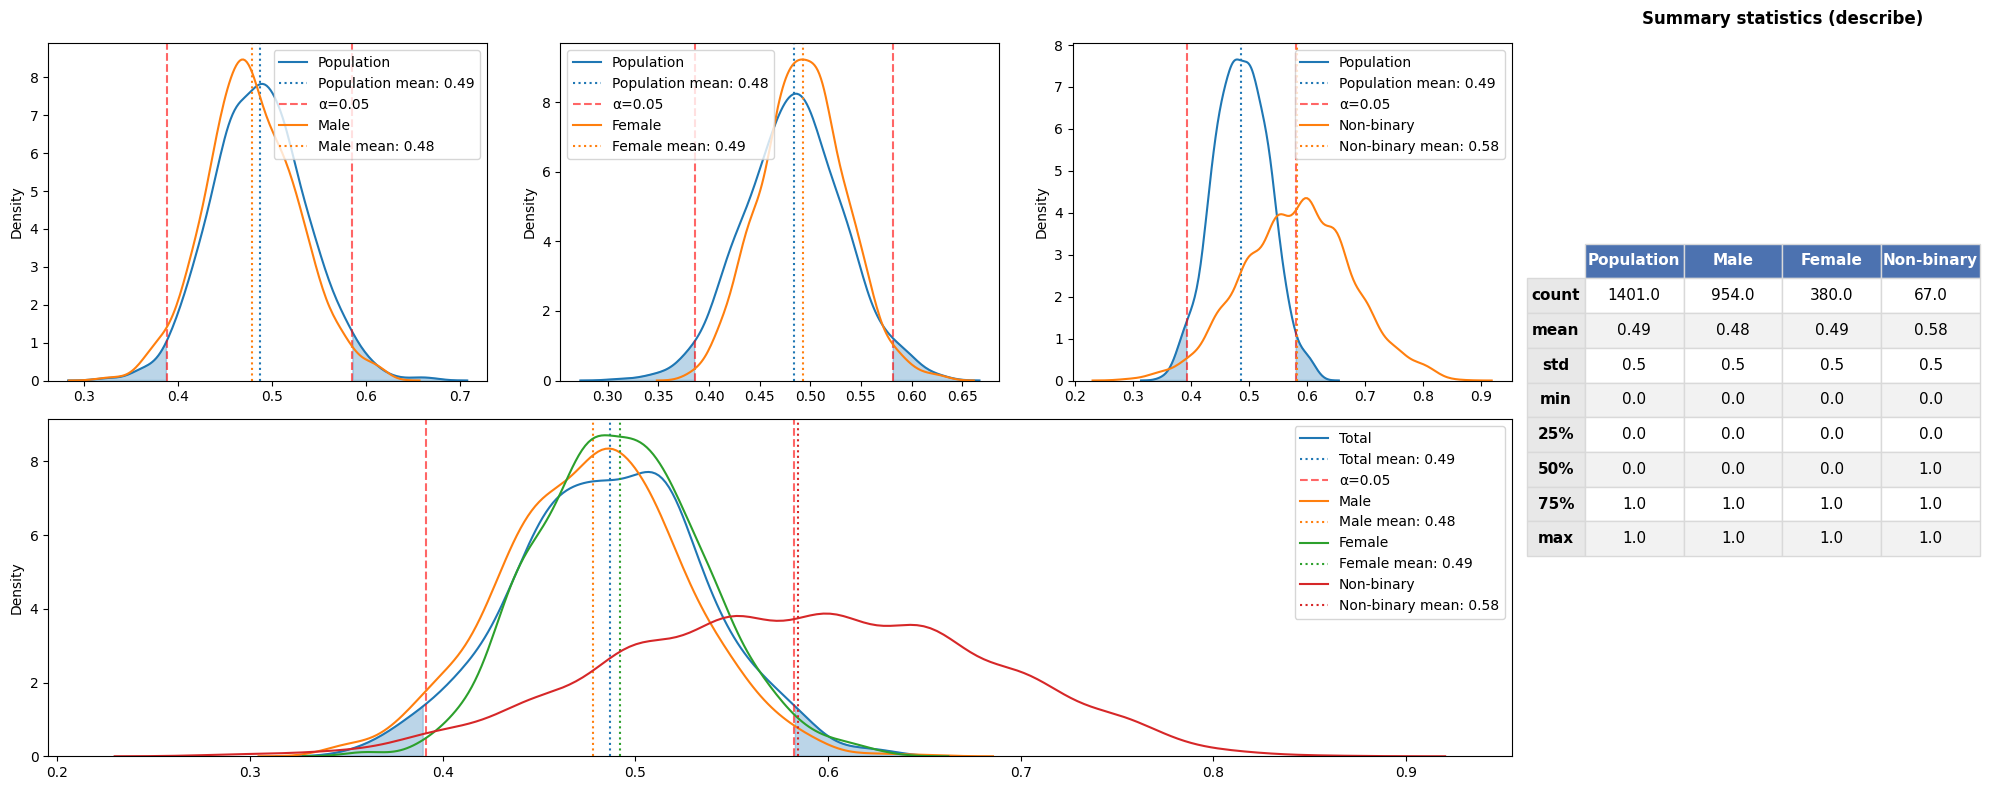

In [49]:
fig, axs = plt.subplot_mosaic(
    [
        ["top1", "top2", "top3", "table"],
        ["bottom", "bottom", "bottom", "table"],
    ],
    figsize=(20, 8),
    width_ratios=[1, 1, 1, 0.9],
)

create_kde_plot(data=discussing.discussing_mental_illness_binary, axs=axs["top1"], label="Population",show_tails=True)
create_kde_plot(data=discussing_male.discussing_mental_illness_binary, axs=axs["top1"], label="Male")
create_kde_plot(data=discussing.discussing_mental_illness_binary, axs=axs["top2"], label="Population",show_tails=True)
create_kde_plot(data=discussing_female.discussing_mental_illness_binary, axs=axs["top2"], label="Female")
create_kde_plot(data=discussing.discussing_mental_illness_binary, axs=axs["top3"], label="Population",show_tails=True)
create_kde_plot(data=discussing_no_binary.discussing_mental_illness_binary, axs=axs["top3"], label="Non-binary",n=20)
create_kde_plot(data=discussing.discussing_mental_illness_binary,axs=axs["bottom"],label="Total",show_tails=True)
create_kde_plot(data=discussing_male.discussing_mental_illness_binary, axs=axs["bottom"], label="Male")
create_kde_plot(data=discussing_female.discussing_mental_illness_binary, axs=axs["bottom"], label="Female")
create_kde_plot(data=discussing_no_binary.discussing_mental_illness_binary, axs=axs["bottom"], label="Non-binary",n=20)

create_describe_table(
    data={
        "Population": discussing.discussing_mental_illness_binary,
        "Male": discussing_male.discussing_mental_illness_binary,
        "Female": discussing_female.discussing_mental_illness_binary,
        "Non-binary": discussing_no_binary.discussing_mental_illness_binary,
    },
    axs=axs["table"],
)

axs["top1"].legend()
axs["top2"].legend()
axs["top3"].legend()
axs["bottom"].legend()
plt.tight_layout()
plt.show()

In [50]:
t, p = stats.ttest_ind(discussing.discussing_mental_illness_binary,discussing_male.discussing_mental_illness_binary)
verdict = "rejected" if p < 0.05 else "not rejected"
comparison = "lower than" if p < 0.05 else "greater than or equal to"
print(f"H0 is {verdict}: the p-value ({p:.4g}) is {comparison} 0.05")

H0 is not rejected: the p-value (0.6747) is greater than or equal to 0.05


In [51]:
t, p = stats.ttest_ind(discussing.discussing_mental_illness_binary,discussing_female.discussing_mental_illness_binary)
verdict = "rejected" if p < 0.05 else "not rejected"
comparison = "lower than" if p < 0.05 else "greater than or equal to"
print(f"H0 is {verdict}: the p-value ({p:.4g}) is {comparison} 0.05")

H0 is not rejected: the p-value (0.8544) is greater than or equal to 0.05


In [52]:
t, p = stats.ttest_ind(discussing.discussing_mental_illness_binary,discussing_no_binary.discussing_mental_illness_binary)
verdict = "rejected" if p < 0.05 else "not rejected"
comparison = "lower than" if p < 0.05 else "greater than or equal to"
print(f"H0 is {verdict}: the p-value ({p:.4g}) is {comparison} 0.05")

H0 is not rejected: the p-value (0.1276) is greater than or equal to 0.05


None of the three comparisons reach statistical significance: comfort discussing mental health
with coworkers does not appear to differ meaningfully by gender in this sample, though the
non-binary estimate (n = 67) is comparatively imprecise, as visible from its wider KDE.

<a id="sec-8"></a>
## 8. Conclusions

**Research Question 1 — Prevalence.** Among respondents with a definitive diagnosis status, an
estimated **56%** report having been diagnosed with a mental illness at some point — a strikingly
high baseline rate for a working population.
- **Country**: statistically significant (both comparisons p < 0.001). Respondents working in
  the USA report a diagnosis rate roughly 20 percentage points higher than the rest of the world
  (≈63.6% vs. ≈42.0%).
- **Gender**: statistically significant for all three groups (all p < 0.001). Women (≈68.5%) and
  non-binary respondents (≈79.6%) report notably higher diagnosis rates than men (≈49.4%).
- **Employment type**: not statistically significant (p ≈ 0.83 for employees, p ≈ 0.55 for the
  self-employed). Self-employed professionals (≈57.7%) and salaried employees (≈55.7%) report
  comparable rates.

**Research Question 2 — Openness.** Overall, only **48.7%** of respondents feel comfortable
discussing a mental health issue with their coworkers — essentially a coin flip. Gender
differences are not statistically significant here (all p > 0.1): the reluctance to speak up
appears to be a shared pattern across genders rather than one driven by a specific group.

**Taken together**, these results suggest that while mental illness is diagnosed at very different
rates across countries and genders, the willingness to talk about it openly at work is uniformly
limited — roughly half of tech workers, regardless of gender, do not feel comfortable discussing
it with coworkers. This points to a workplace culture gap that affects the whole tech workforce,
not just the subgroups with the highest diagnosis rates.

**Limitations**
- The survey is voluntary and self-reported (OSMI's *Mental Health in Tech Survey*), so results
  likely reflect a self-selected group of respondents who were already engaged with the topic of
  mental health, and may not generalize to the tech workforce as a whole.
- The sample is geographically skewed toward the USA, and "Outside USA" groups together many
  countries with very different cultures, healthcare systems, and attitudes toward mental health
  and disclosure.
- Gender groups are unbalanced: the non-binary/"other" group is small in both research questions
  (n = 98 and n = 67), so its estimates carry more uncertainty, visible in the wider KDE curves.
- Ambiguous answers ("Maybe", "Don't Know", "No answer") were excluded rather than imputed,
  which further reduces sample sizes and could introduce bias if these responses are not missing
  at random.
- Each research question involves several independent t-tests without a multiple-comparison
  correction (e.g., Bonferroni), which increases the family-wise chance of at least one false
  positive.
- All findings are correlational. For example, the higher diagnosis rate in the USA compared to
  the rest of the world could reflect differences in access to diagnosis and care, or in cultural
  openness to disclosing a diagnosis, rather than a true difference in the underlying prevalence
  of mental illness.

<a id="sec-9"></a>
## 9. References & Data Source

- Dataset: [Mental Health in the Tech Industry](https://www.kaggle.com/datasets/anth7310/mental-health-in-the-tech-industry)
  (Kaggle), originally collected by [Open Sourcing Mental Illness (OSMI)](https://osmhelp.org/)
  through its annual *Mental Health in Tech Survey*, 2014–2019.
- Statistical test: independent two-sample t-test (`scipy.stats.ttest_ind`), α = 0.05.